# Word elimination (prototype solver, v3)

This notebook is the hand-edited prototype of the filtering logic in [`Wordle_Solver_v0.py`](Wordle_Solver_v0.py).

Each game gets its own cell. Fill in the clues by hand:
- `in_word`: green and yellow letters.
- `not_in_word`: gray letters.
- Per-slot conditions: `df['3rd'] == 'a'` for a green; `~df['2nd'].isin(list('ep'))` for yellows that ruled out a slot.

The cell then intersects the row indices that satisfy every condition. The four game cells (`top_left`, `top_right`, `bottom_left`, `bottom_right`) were used to play four boards at once.

Run it from the `Wordle/` folder so the word list loads from disk.


In [1]:
import pandas as pd, numpy as np, os,glob
import string

In [2]:
# from google.colab import drive
# drive.mount('/content/drive/')

In [3]:
import matplotlib.pyplot as plt

In [4]:
## the parsed word list lives next to this notebook in the repo;
## download it only if it's missing (e.g. when running on Colab)
fname = '5 letter words parsed - NLTK Words Corpora - v0.csv'
if not os.path.exists(fname):
    import urllib.parse, urllib.request
    url = ('https://raw.githubusercontent.com/JoeyWilkes12/Projects1/master/Wordle/'
           + urllib.parse.quote(fname))
    urllib.request.urlretrieve(url, fname)

In [5]:
# p = 'drive/MyDrive/<your-folder>/WORDLE/NLTK Word Copora Parsed/csv\'s/'
# p = None
# os.listdir(p)

In [6]:
sorted(f for f in os.listdir() if f.endswith('.csv'))

['5 letter words parsed - NLTK Words Corpora - v0.csv',
 'Joined NLTK & Github 5 letter words v0.csv',
 'madalynrose list of 5 letter words parsed v0.csv']

In [7]:
p = '' # don't need to mount when the dataset is publically available
# df = pd.read_csv(p + '6 letter words parsed - NLTK Words Corpora - v0.csv')
# p = 'drive/MyDrive/<your-folder>/WORDLE/'
# os.listdir(p)
df = pd.read_csv(p + '5 letter words parsed - NLTK Words Corpora - v0.csv')
# df = pd.read_csv(p + '7 letter words parsed - NLTK Words Corpora - v0.csv')

In [8]:
#vague, reset, eerie, pixie, weave, bathe,
## forbid, tingle, sacred, tattoo
# df['word'].sample(20)

In [9]:
# 'racecar' in set(df['word'].values) ## flaw

In [10]:
alphabet_string = string.ascii_lowercase
alphabet_list = list(alphabet_string)
# alphabet_list

In [11]:
set(alphabet_list) - set('chainbreadstrum') # how to find words that have these letters

{'f', 'g', 'j', 'k', 'l', 'o', 'p', 'q', 'v', 'w', 'x', 'y', 'z'}

In [12]:
## I thought this would be needed but it wasn't
# for col in alphabet_list:
#     df.loc[:,col] = df.loc[:,col].map({True:1,False:0})

In [13]:
# 'ethyl' in set(df.word.values)

# Need to turn into classes

In [14]:
print('top left')
## now I just need to expand these lists to update given additional guesses
# in_word = ['t','e']
in_word = list('ar')
# in_word = []
# in_word = ['s','e','i','t'] ##just to see
# in_word = set('reive') ##yellow & greens
not_in_word = []
not_in_word = set(list('wearyapart')) - set(in_word) ## black letters


ind = set(df.index)
# print(len(ind))
for iw in in_word:
    ind = ind.intersection(set(df.loc[df[iw.lower()] == 1].index))
# print(len(ind))
for niw in not_in_word:
    ind = ind.intersection(set(df.loc[df[niw] == 0].index))
# print(len(ind))

ind = ind.intersection(set(df.loc[
    # (df['1st'] == 'c') & 
     (~df['1st'].isin(list('wa'))) & 

    # (df['2nd'] == 'h') #&
    (~df['2nd'].isin(list('ep'))) & 

    (df['3rd'] == 'a') & 
    # (~df['3rd'].isin(list('rn'))) & 

    (df['4th'] == 'r') & 
    # (~df['4th'].isin(list('n'))) & 

    # (df['5th'] == 'y') #&
    (~df['5th'].isin(list('yt'))) #& 

    # (df['6th'] == 'e') &
    # (~df['6th'].isin(list('t')) ) &

    #   (df['7th'] == 'd') &
    # (~df['7th'].isin(['s']) ) #&  

 ].index)) 


remaining_words = list(df.loc[sorted(ind)]['word'].values)
top_left = remaining_words
## cothy is not in acceptable word list
## turns out zloty is accepted 
# remaining_words = set(remaining_words) - set(['cothy']) ##remove words that have already been guessed

for i,x in enumerate(remaining_words):
    i += 1
    if i % 5 == 0:
        print(x)
    else:
        print(x,end=', ')
print('\n\n')
print('the hardest part is when we know there are not more than one of a certain letter - valuable information but hard to code in, need to change from boolean to number of occurances')
print('number of remaining words is',len(remaining_words))

top left
urari, liard, guard, guara, ziara
board, coarb, usara, claro, fiard
hoard, inarm, izard, unarm, quarl
quark, unark, uzara, bhara, snarl
gnarl, knark, chard, charr, smarm
clark, scarf, chark, shark, scarn
sharn, snark, charm, shard, 


the hardest part is when we know there are not more than one of a certain letter - valuable information but hard to code in, need to change from boolean to number of occurances
number of remaining words is 34


In [15]:
print('top right')
## now I just need to expand these lists to update given additional guesses
# in_word = ['t','e']
in_word = list('wf')
# in_word = []
# in_word = ['s','e','i','t'] ##just to see
# in_word = set('reive') ##yellow & greens
not_in_word = []
not_in_word = set(list('trashrignclud')) - set(in_word) ## black letters


ind = set(df.index)
# print(len(ind))
for iw in in_word:
    ind = ind.intersection(set(df.loc[df[iw.lower()] == 1].index))
# print(len(ind))
for niw in not_in_word:
    ind = ind.intersection(set(df.loc[df[niw] == 0].index))
# print(len(ind))

# ind = ind.intersection(set(df.loc[
#     # (df['1st'] == 'b') & 
#      (~df['1st'].isin(list('d'))) & 

#     (df['2nd'] == 'a') &
#     # (~df['2nd'].isin(list('ah'))) #& 

#     # (df['3rd'] == 'r') & 
#     # (~df['3rd'].isin(list('a'))) & 

#     # (df['4th'] == 't') #& 
#     (~df['4th'].isin(list('a'))) & 

#     (df['5th'] == 'e') #&
#     # (~df['5th'].isin(list('l'))) #& 

#     # (df['6th'] == 'e') &
#     # (~df['6th'].isin(list('t')) ) &

#     #   (df['7th'] == 'd') &
#     # (~df['7th'].isin(['s']) ) #&  

#  ].index)) 


remaining_words = list(df.loc[sorted(ind)]['word'].values)
## cothy is not in acceptable word list
## turns out zloty is accepted 
# remaining_words = set(remaining_words) - set(['cothy']) ##remove words that have already been guessed
top_right = remaining_words
for i,x in enumerate(remaining_words):
    i += 1
    if i % 5 == 0:
        print(x)
    else:
        print(x,end=', ')
print('\n\n')
print('the hardest part is when we know there are not more than one of a certain letter - valuable information but hard to code in, need to change from boolean to number of occurances')
print('number of remaining words is',len(remaining_words))

top right
woofy, 


the hardest part is when we know there are not more than one of a certain letter - valuable information but hard to code in, need to change from boolean to number of occurances
number of remaining words is 1


In [16]:
print('bottom left')
## now I just need to expand these lists to update given additional guesses
# in_word = ['t','e']
# in_word = list('plas')
in_word = []
# in_word = ['s','e','i','t'] ##just to see
# in_word = set('reive') ##yellow & greens
not_in_word = []
not_in_word = set(list('saucebraid')) - set(in_word)  ## black letters
# not_in_word -= set(list('a'))

ind = set(df.index)
# print(len(ind))
for iw in in_word:
    ind = ind.intersection(set(df.loc[df[iw.lower()] == 1].index))
# print(len(ind))
for niw in not_in_word:
    ind = ind.intersection(set(df.loc[df[niw] == 0].index))
# print(len(ind))

# ind = ind.intersection(set(df.loc[
#     # (df['1st'] == 'l') & 
#      (~df['1st'].isin(list('p'))) & 

#     (df['2nd'] == 'l') &
#     # (~df['2nd'].isin(list('a'))) & 

#     (df['3rd'] == 'a') & 
#     # (~df['3rd'].isin(list('lu'))) & 

#     (df['4th'] == 's') #& 
#     # (~df['4th'].isin(list('a'))) #& 

#     # (df['5th'] == 'y') #&
#     # (~df['5th'].isin(list('n'))) #& 

#     # (df['6th'] == 'e') &
#     # (~df['6th'].isin(list('t')) ) &

#     #   (df['7th'] == 'd') &
#     # (~df['7th'].isin(['s']) ) #&  

#  ].index)) 


remaining_words = list(df.loc[sorted(ind)]['word'].values)
## cothy is not in acceptable word list
## turns out zloty is accepted 
# remaining_words = set(remaining_words) - set(['cothy']) ##remove words that have already been guessed
bottom_left = remaining_words
for i,x in enumerate(remaining_words):
    i += 1
    if i % 5 == 0:
        print(x)
    else:
        print(x,end=', ')
print('\n\n')
print('the hardest part is when we know there are not more than one of a certain letter - valuable information but hard to code in, need to change from boolean to number of occurances')
print('number of remaining words is',len(remaining_words))

bottom left
hotly, onymy, goofy, nooky, mothy
toffy, folly, oxfly, jowpy, hooly
footy, nonly, totty, tolyl, toppy
jowly, hoofy, xylol, moggy, ology
lowly, woofy, nylon, lolly, tolly
loony, folky, zloty, tommy, oolly
molly, lofty, fonly, foggy, loopy
nonyl, pooly, oftly, xylon, foppy
monny, holly, phony, hooky, poppy
yolky, jolly, loppy, mommy, wonky
poggy, pommy, woozy, hoppy, polyp
moony, zygon, golly, moppy, jolty
towny, hoggy, potty, jotty, hypho
pylon, myopy, toyon, fogon, month
thoft, plook, wootz, mowth, lymph
pygmy, phono, thong, howff, thoom
flown, owght, potoo, ghoom, ponto
jhool, toxon, thowt, xylyl, gloom
whoof, lotto, motto, mooth, hollo
knoll, nohow, nymph, thymy, whoop
glyph, potto, known, otkon, tooth
flong, ovolo, lowth, photo, 


the hardest part is when we know there are not more than one of a certain letter - valuable information but hard to code in, need to change from boolean to number of occurances
number of remaining words is 109


In [17]:
print('bottom right')
## now I just need to expand these lists to update given additional guesses
# in_word = ['t','e']
in_word = list('plan')
# in_word = []
# in_word = ['s','e','i','t'] ##just to see
# in_word = set('reive') ##yellow & greens
not_in_word = []
not_in_word = set(list('saucebraidpylon')) - set(in_word) ## black letters


ind = set(df.index)
# print(len(ind))
for iw in in_word:
    ind = ind.intersection(set(df.loc[df[iw.lower()] == 1].index))
# print(len(ind))
for niw in not_in_word:
    ind = ind.intersection(set(df.loc[df[niw] == 0].index))
# print(len(ind))

ind = ind.intersection(set(df.loc[
    (df['1st'] == 'p') & 
    #  (~df['1st'].isin(list('p'))) & 

    # (df['2nd'] == 'a') &
    # (~df['2nd'].isin(list('p'))) & 

    (df['3rd'] == 'a') & 
    # (~df['3rd'].isin(list('a'))) & 

    # (df['4th'] == 'n') & 
    # (~df['4th'].isin(list('li'))) & 

    # (df['5th'] == 'e') #&
    (~df['5th'].isin(list('n'))) #& 

    # (df['6th'] == 'e') &
    # (~df['6th'].isin(list('t')) ) &

    #   (df['7th'] == 'd') &
    # (~df['7th'].isin(['s']) ) #&  

 ].index)) 


remaining_words = list(df.loc[sorted(ind)]['word'].values)
## cothy is not in acceptable word list
## turns out zloty is accepted 
# remaining_words = set(remaining_words) - set(['cothy']) ##remove words that have already been guessed
bottom_right = remaining_words
for i,x in enumerate(remaining_words):
    i += 1
    if i % 5 == 0:
        print(x)
    else:
        print(x,end=', ')
print('\n\n')
print('the hardest part is when we know there are not more than one of a certain letter - valuable information but hard to code in, need to change from boolean to number of occurances')
print('number of remaining words is',len(remaining_words))

bottom right
plang, plant, plank, 


the hardest part is when we know there are not more than one of a certain letter - valuable information but hard to code in, need to change from boolean to number of occurances
number of remaining words is 3


In [18]:
'fewer' in df.word.values # not in the NLTK dataset?
# maybe join the two datasets

False

In [19]:
# print(top_left,top_right,bottom_left,bottom_right,sep='\n\n')
# print(f'top_left \t{top_left}')
# print(f'top right \t{top_right}')
print(f'bottom left \t {bottom_left}')
print(f'bottom right \t{bottom_right}')
# set(np.random.choice(list(bottom_left))).intersection(np.random.choice(list(top_right)))

bottom left 	 ['hotly', 'onymy', 'goofy', 'nooky', 'mothy', 'toffy', 'folly', 'oxfly', 'jowpy', 'hooly', 'footy', 'nonly', 'totty', 'tolyl', 'toppy', 'jowly', 'hoofy', 'xylol', 'moggy', 'ology', 'lowly', 'woofy', 'nylon', 'lolly', 'tolly', 'loony', 'folky', 'zloty', 'tommy', 'oolly', 'molly', 'lofty', 'fonly', 'foggy', 'loopy', 'nonyl', 'pooly', 'oftly', 'xylon', 'foppy', 'monny', 'holly', 'phony', 'hooky', 'poppy', 'yolky', 'jolly', 'loppy', 'mommy', 'wonky', 'poggy', 'pommy', 'woozy', 'hoppy', 'polyp', 'moony', 'zygon', 'golly', 'moppy', 'jolty', 'towny', 'hoggy', 'potty', 'jotty', 'hypho', 'pylon', 'myopy', 'toyon', 'fogon', 'month', 'thoft', 'plook', 'wootz', 'mowth', 'lymph', 'pygmy', 'phono', 'thong', 'howff', 'thoom', 'flown', 'owght', 'potoo', 'ghoom', 'ponto', 'jhool', 'toxon', 'thowt', 'xylyl', 'gloom', 'whoof', 'lotto', 'motto', 'mooth', 'hollo', 'knoll', 'nohow', 'nymph', 'thymy', 'whoop', 'glyph', 'potto', 'known', 'otkon', 'tooth', 'flong', 'ovolo', 'lowth', 'photo']
bott

In [20]:
print(top_right,bottom_left,sep='\n\n')
set(np.random.choice(list(bottom_left))).intersection(np.random.choice(list(top_right)))

['woofy']

['hotly', 'onymy', 'goofy', 'nooky', 'mothy', 'toffy', 'folly', 'oxfly', 'jowpy', 'hooly', 'footy', 'nonly', 'totty', 'tolyl', 'toppy', 'jowly', 'hoofy', 'xylol', 'moggy', 'ology', 'lowly', 'woofy', 'nylon', 'lolly', 'tolly', 'loony', 'folky', 'zloty', 'tommy', 'oolly', 'molly', 'lofty', 'fonly', 'foggy', 'loopy', 'nonyl', 'pooly', 'oftly', 'xylon', 'foppy', 'monny', 'holly', 'phony', 'hooky', 'poppy', 'yolky', 'jolly', 'loppy', 'mommy', 'wonky', 'poggy', 'pommy', 'woozy', 'hoppy', 'polyp', 'moony', 'zygon', 'golly', 'moppy', 'jolty', 'towny', 'hoggy', 'potty', 'jotty', 'hypho', 'pylon', 'myopy', 'toyon', 'fogon', 'month', 'thoft', 'plook', 'wootz', 'mowth', 'lymph', 'pygmy', 'phono', 'thong', 'howff', 'thoom', 'flown', 'owght', 'potoo', 'ghoom', 'ponto', 'jhool', 'toxon', 'thowt', 'xylyl', 'gloom', 'whoof', 'lotto', 'motto', 'mooth', 'hollo', 'knoll', 'nohow', 'nymph', 'thymy', 'whoop', 'glyph', 'potto', 'known', 'otkon', 'tooth', 'flong', 'ovolo', 'lowth', 'photo']


{'f', 'o', 'w'}

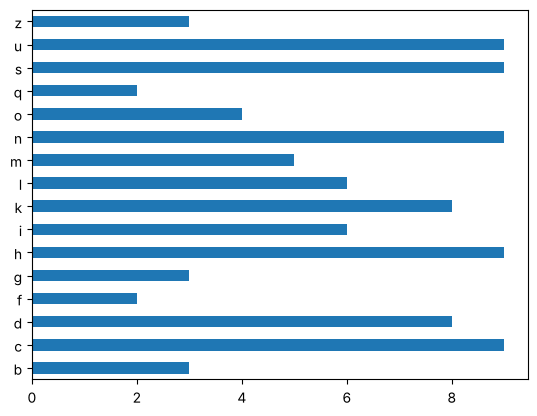

In [21]:
## analysis on remaining letters & words
## rwdf = remaining words df
in_word = list('ar') ## top_left (same green/yellow letters as the top_left cell)
# in_word = list('tha') ## top_right
# in_word = list('o') ## bottom_left
# in_word = list('tus') ## bottom_right

rwdf = pd.DataFrame([list(x) for x in top_left])
# rwdf = pd.DataFrame([list(x) for x in top_right])
# rwdf = pd.DataFrame([list(x) for x in bottom_left])
# rwdf = pd.DataFrame([list(x) for x in bottom_right])

letters, counts = np.unique(rwdf.values.ravel(),return_counts=True)
# plt.bar(letters,counts)
# plt.show()
S = pd.Series(counts,index=letters)
S.drop(in_word,inplace=True,errors='ignore') ## a letter may be absent from every remaining word
S.sort_index().plot(kind='barh')
plt.show()

In [22]:
S = pd.Series(counts,index=letters)
# S[['a','e','i','o','u','y']]
S.reindex(['a','i','o','u','y'],fill_value=0) ## 0 for vowels not in any remaining word

a    39
i     6
o     4
u     9
y     0
dtype: int64

# Pick some random words

In [23]:
##generator - scoring solutions
wordle = 'atrium'

# guess1 = 'layout?'
# guess1 = 'l?a?y?out!'
guess1 = 't?att' ## this doesn't quite work 
guess1 = 'tr?a?i!t?s'


g = guess1 
g.split('?')
## how many question marks are there, if length of g.split('?') == 1 then there is no question mark
q = g.split('?')
ex = g.split('!') ##ex for exclamation point
yellows = []
greens = []
if len(q) > 1:
    ## l[:-1] because we want to exclude the '' 
    yellows = [x[-1] for x in q[:-1]]
print('add in test case that it shouldnt start with question mark, or have two of them or punction beyond letters')
if len(ex) > 1:
    ## l[:-1] because we want to exclude the '' 
    greens = [x[-1] for x in ex[:-1]]
print('what if there are no exclamation points')
blacks = set(g) - set(yellows) - set(greens) - set(['?','!'])
print(blacks,yellows,greens,sep='\n\n')
print('this isnt giving the results of what are question marks or exclamation points, this is for solver not the game')
print('with yellows, its also important to know which place was yellow - when there was doubles ')


add in test case that it shouldnt start with question mark, or have two of them or punction beyond letters
what if there are no exclamation points
{'s'}

['r', 'a', 't']

['i']
this isnt giving the results of what are question marks or exclamation points, this is for solver not the game
with yellows, its also important to know which place was yellow - when there was doubles 
